# ステップ1-1 演習: 1変数データ

この Notebook は、本文 [ステップ1-1 記述統計: 1変数データ](../docs/step1-1_univariate.md) の演習です。本文の手計算の例を Python で検算し、続いて工学の例題として、2台のセンサの繰り返し測定のばらつきを比べます。

上のセルから順に実行してください。模擬データを作る節（3節・4節）では、それぞれの節の始めで乱数の生成器を同じシードから作り直します。そのため、節を飛ばしたり再実行したりしても、同じ版の NumPy なら同じ模擬データになります（NumPy の版によっては、値がわずかに変わることがあります）。

## 1. 準備

使うパッケージを読み込み、乱数のシードを決めます。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 乱数のシード。模擬データを作る節の始めで、この値から生成器を作り直す
SEED = 20261017

## 2. 本文の手計算を検算する

### 2-1. 6個の測定値の代表値と散らばり

本文の4節・6節で手計算した、部品の長さの6個の測定値（単位 mm）です。`ddof=1` は、分散を $n-1$ で割る指定です。

In [2]:
x = np.array([10.1, 9.9, 10.0, 10.2, 9.8, 10.6])

mean = x.mean()
var = x.var(ddof=1)
sd = x.std(ddof=1)

print(f"平均       {mean:.3f}")
print(f"中央値     {np.median(x):.3f}")
print(f"範囲       {x.max() - x.min():.3f}")
print(f"分散       {var:.4f}")
print(f"標準偏差   {sd:.4f}")
print(f"変動係数   {sd / mean * 100:.2f} %")
print(f"10.6 のz得点 {(10.6 - mean) / sd:.2f}")

平均       10.100
中央値     10.050
範囲       0.800
分散       0.0800
標準偏差   0.2828
変動係数   2.80 %
10.6 のz得点 1.77


### 2-2. 四分位数の求め方の違い

本文の5節では、データを下半分と上半分に分け、それぞれの中央値を第1四分位数・第3四分位数としました。NumPy の `np.percentile` の既定は、順位の間を直線で補う別の求め方なので、値が少し変わります。matplotlib の箱ひげ図も、この既定の求め方を使います。

In [3]:
def quartiles_by_halves(data):
    """下半分と上半分の中央値を第1・第3四分位数とする（個数が奇数なら中央の値は両方から除く）"""
    s = np.sort(data)
    n = len(s)
    return np.median(s[: n // 2]), np.median(s[(n + 1) // 2 :])


q1, q3 = quartiles_by_halves(x)
iqr = q3 - q1
print(f"半分に分ける方法      Q1={q1:.3f}  Q3={q3:.3f}  四分位範囲={iqr:.3f}"
      f"  外れ値の目安 {q1 - 1.5 * iqr:.3f} 〜 {q3 + 1.5 * iqr:.3f}")
p25, p75 = np.percentile(x, [25, 75])
iqr_p = p75 - p25
print(f"np.percentile の既定  Q1={p25:.3f}  Q3={p75:.3f}  四分位範囲={iqr_p:.3f}"
      f"  外れ値の目安 {p25 - 1.5 * iqr_p:.3f} 〜 {p75 + 1.5 * iqr_p:.3f}")

半分に分ける方法      Q1=9.900  Q3=10.200  四分位範囲=0.300  外れ値の目安 9.450 〜 10.650
np.percentile の既定  Q1=9.925  Q3=10.175  四分位範囲=0.250  外れ値の目安 9.550 〜 10.550


### 2-3. 度数分布表からの平均と分散

本文の3節・6節の度数分布表（10個の測定値を3つの階級にまとめたもの）から、階級値を使って平均と分散を求めます。

In [4]:
class_marks = np.array([9.8, 10.0, 10.2])
counts = np.array([2, 5, 3])
n_total = counts.sum()

mean_t = (class_marks * counts).sum() / n_total
var_t = (counts * (class_marks - mean_t) ** 2).sum() / (n_total - 1)
print(f"相対度数     {counts / n_total}")
print(f"累積相対度数 {np.cumsum(counts) / n_total}")
print(f"平均         {mean_t:.3f}")
print(f"分散         {var_t:.5f}")
print(f"標準偏差     {np.sqrt(var_t):.4f}")

相対度数     [0.2 0.5 0.3]
累積相対度数 [0.2 0.7 1. ]
平均         10.020
分散         0.02178
標準偏差     0.1476


### 2-4. 歪度

本文の7節の式（ $n$ で割った分散の平方根を使う）で、6個の測定値の歪度を求めます。`scipy.stats.skew` の既定も同じ式です。

In [5]:
z_pop = (x - mean) / x.std(ddof=0)
print(f"式どおりに計算      {np.mean(z_pop**3):.3f}")
print(f"scipy.stats.skew    {stats.skew(x):.3f}")

式どおりに計算      0.871
scipy.stats.skew    0.871


### 2-5. ジニ係数

本文の8節の、4台の装置の不具合の件数（1, 1, 2, 6 件）から、ローレンツ曲線の点とジニ係数を求めます。

累積の割合（装置） [0.   0.25 0.5  0.75 1.  ]
累積の割合（件数） [0.  0.1 0.2 0.4 1. ]
ジニ係数           0.400


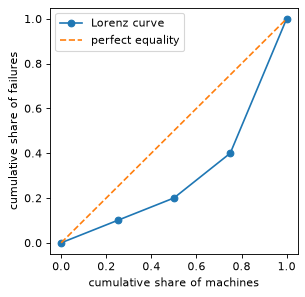

In [6]:
failures = np.sort(np.array([1, 1, 2, 6]))
share_x = np.arange(len(failures) + 1) / len(failures)
share_y = np.concatenate([[0.0], np.cumsum(failures) / failures.sum()])

# ローレンツ曲線の下の面積を台形の和で求め、ジニ係数 = 1 - 2 × 面積 とする
area = np.sum((share_x[1:] - share_x[:-1]) * (share_y[1:] + share_y[:-1]) / 2)
print(f"累積の割合（装置） {share_x}")
print(f"累積の割合（件数） {share_y}")
print(f"ジニ係数           {1 - 2 * area:.3f}")

plt.figure(figsize=(4, 4))
plt.plot(share_x, share_y, marker="o", label="Lorenz curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="perfect equality")
plt.xlabel("cumulative share of machines")
plt.ylabel("cumulative share of failures")
plt.legend()
plt.show()

### 2-6. 1次式の変換

本文の6-5節の例です。6個の測定値（mm）を、呼び寸法 10 mm からのずれ（μm）に換算すると、平均と標準偏差がどう変わるかを確かめます。

In [7]:
y = 1000 * (x - 10.0)
print(f"変換後の値   {np.round(y, 1)}")
print(f"平均         {y.mean():.1f}")
print(f"標準偏差     {y.std(ddof=1):.1f}")

変換後の値   [ 100. -100.    0.  200. -200.  600.]
平均         100.0
標準偏差     282.8


## 3. 分布の形と、歪度・尖度

本文の3節・7節で見た分布の形を、模擬データで確かめます。同じ個数（1000個）で、形の違う3つのデータを作ります。

- 左右対称の山形: 正規分布に従う測定値
- 右に裾が長い: 対数正規分布に従う値（例: 作業にかかる時間のように、0より小さくならず、たまに大きな値が出るもの）
- 平らな形: 一様分布に従う値（ある範囲のどの値も同じように出るもの）

尖度は、正規分布で0になるように3を引いた値（`scipy.stats.kurtosis` の既定）を表示します。

symmetric (normal)         平均 10.021  中央値 10.020  歪度 -0.014  尖度  0.116
right-skewed (lognormal)   平均  1.181  中央値  0.978  歪度  1.557  尖度  2.991
flat (uniform)             平均  0.509  中央値  0.521  歪度 -0.060  尖度 -1.211


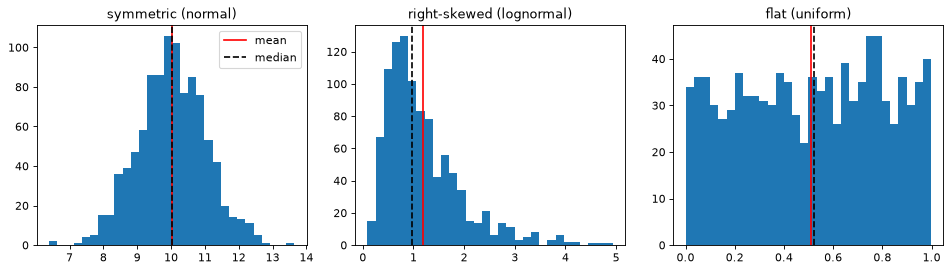

In [8]:
rng = np.random.default_rng(seed=SEED)
shapes = {
    "symmetric (normal)": rng.normal(loc=10.0, scale=1.0, size=1000),
    "right-skewed (lognormal)": rng.lognormal(mean=0.0, sigma=0.6, size=1000),
    "flat (uniform)": rng.uniform(low=0.0, high=1.0, size=1000),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, data) in zip(axes, shapes.items()):
    ax.hist(data, bins=30)
    ax.axvline(data.mean(), color="red", label="mean")
    ax.axvline(np.median(data), color="black", linestyle="--", label="median")
    ax.set_title(name)
    print(f"{name:26s} 平均 {data.mean():6.3f}  中央値 {np.median(data):6.3f}"
          f"  歪度 {stats.skew(data):6.3f}  尖度 {stats.kurtosis(data):6.3f}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. 工学の例題: 2台のセンサのばらつきを比べる

長さが 10.000 mm と分かっている基準のブロック（ゲージブロック）を、2台のセンサ A・B でそれぞれ50回ずつ測ったとします。模擬データの条件は次のとおりです。

- センサ A: 偏り（基準からのずれ）は無く、ばらつきの標準偏差は 0.020 mm
- センサ B: 平均して +0.030 mm ずれて読む偏りがあり、ばらつきの標準偏差は 0.010 mm。さらに50回のうち2回、ノイズで +0.150 mm 大きく読んだ値が混じる

データを読む側は、この条件を知らないものとして、要約統計量とグラフから2台の特徴を読み取ります。

In [9]:
rng = np.random.default_rng(seed=SEED)
n = 50
true_length = 10.000

sensor_a = true_length + rng.normal(loc=0.0, scale=0.020, size=n)
sensor_b = true_length + 0.030 + rng.normal(loc=0.0, scale=0.010, size=n)
spikes = rng.choice(n, size=2, replace=False)
sensor_b[spikes] += 0.150

### 4-1. 要約統計量

中心（平均・中央値）、散らばり（標準偏差・四分位範囲・最小と最大）、形（歪度）を並べます。四分位数は本文と同じ「半分に分ける方法」で求めます。

In [10]:
def summarize(name, data):
    """1変数データの要約統計量を1行で表示する"""
    q1, q3 = quartiles_by_halves(data)
    print(f"{name}  平均 {data.mean():.4f}  中央値 {np.median(data):.4f}"
          f"  標準偏差 {data.std(ddof=1):.4f}  四分位範囲 {q3 - q1:.4f}"
          f"  最小 {data.min():.4f}  最大 {data.max():.4f}  歪度 {stats.skew(data):.2f}")


summarize("A", sensor_a)
summarize("B", sensor_b)

A  平均 9.9996  中央値 10.0020  標準偏差 0.0178  四分位範囲 0.0222  最小 9.9563  最大 10.0389  歪度 -0.40
B  平均 10.0345  中央値 10.0309  標準偏差 0.0302  四分位範囲 0.0118  最小 10.0098  最大 10.1902  歪度 4.25


### 4-2. ヒストグラムと箱ひげ図

基準の長さ 10.000 mm を破線で示します。箱ひげ図の白丸は、外れ値の目安（四分位数から四分位範囲の1.5倍より外）に当たる点です。matplotlib の箱ひげ図は四分位数を `np.percentile` の既定の方法で求めるため、本文の方法と箱の端や白丸の点が少し異なることがあります。

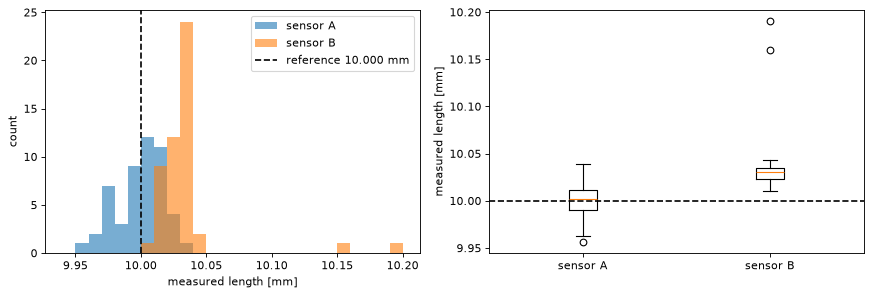

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

bins = np.linspace(9.94, 10.20, 27)
axes[0].hist(sensor_a, bins=bins, alpha=0.6, label="sensor A")
axes[0].hist(sensor_b, bins=bins, alpha=0.6, label="sensor B")
axes[0].axvline(true_length, color="black", linestyle="--", label="reference 10.000 mm")
axes[0].set_xlabel("measured length [mm]")
axes[0].set_ylabel("count")
axes[0].legend()

axes[1].boxplot([sensor_a, sensor_b], whis=1.5)
axes[1].set_xticks([1, 2], ["sensor A", "sensor B"])
axes[1].axhline(true_length, color="black", linestyle="--")
axes[1].set_ylabel("measured length [mm]")

plt.tight_layout()
plt.show()

### 4-3. 外れ値の目安に当たる点を確かめる

センサ A・B のそれぞれについて、本文の方法で求めた外れ値の目安の範囲の外にある点を取り出します。続いて、B から外れた点を除いた場合の要約統計量と比べます。除いてよいかどうかは数値だけでは決まらないので、ここでは「除くと何が変わるか」を見るだけにします。

In [12]:
def outside_fences(data):
    """本文の方法の四分位数で、外れ値の目安の範囲の外にあるかを真偽の配列で返す"""
    q1, q3 = quartiles_by_halves(data)
    iqr = q3 - q1
    return (data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)


out_a = outside_fences(sensor_a)
out_b = outside_fences(sensor_b)
print(f"A の目安の外の点  {np.round(sensor_a[out_a], 4)}")
print(f"B の目安の外の点  {np.round(sensor_b[out_b], 4)}")
summarize("B（全点）    ", sensor_b)
summarize("B（目安の外を除く）", sensor_b[~out_b])

A の目安の外の点  []
B の目安の外の点  [10.1596 10.1902]
B（全点）      平均 10.0345  中央値 10.0309  標準偏差 0.0302  四分位範囲 0.0118  最小 10.0098  最大 10.1902  歪度 4.25
B（目安の外を除く）  平均 10.0287  中央値 10.0304  標準偏差 0.0081  四分位範囲 0.0121  最小 10.0098  最大 10.0435  歪度 -0.45


## 5. まとめ

- センサ A は、平均・中央値が基準の 10.000 mm に近く、偏りは小さい。ばらつきは、四分位範囲や、B の外れた2点を除いた標準偏差と比べると、B より大きい。
- センサ B は、平均・中央値とも基準より約 0.03 mm 大きく、偏りがある。全点の標準偏差は A より大きいが、これは大きく外れた2点のためで、2点を除いたばらつきは A より小さい。
- 外れ値は平均と標準偏差を大きく動かすが、中央値と四分位範囲はほとんど動かさない。外れ値に左右されにくい指標を並べて見ると、外れ値の影響に気づきやすい。
- 「偏りが小さいこと」と「ばらつきが小さいこと」は別の性質で、1つの指標だけではセンサの良し悪しを判断できない。

読み方の詳しい説明は、本文の9節にあります。